# Семинар 9. Индексы и квантизация

Найдём top-100 объектов по сходству с пользовательским вектором.
Перед поиском нормируем векторы пользователей и объектов до единичной длины:

$$\bar x=\frac{x}{\|x\|_2},\qquad \bar y=\frac{y}{\|y\|_2}.$$

Скор — косинусное сходство, которое на нормированных векторах равно скалярному произведению:

$$s(x,y)=\bar x^T\bar y.$$

Сравним FlatIP, HNSW, IVF и PQ. Для итогового сравнения подберём конфигурации
с ANN Recall не ниже 99% на валидационных запросах, затем проверим их на отдельной выборке.


In [63]:
import importlib.util
import subprocess
import sys

packages = {
    'faiss': 'faiss-cpu==1.13.2', 'gdown': 'gdown==5.2.0',
    'h5py': 'h5py>=3.10', 'numpy': 'numpy>=1.26,<3', 'pandas': 'pandas>=2.2',
    'matplotlib': 'matplotlib>=3.8', 'threadpoolctl': 'threadpoolctl>=3.5',
}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])


In [64]:
import gc
import json
import os
import platform
import time
from concurrent.futures import ThreadPoolExecutor
from html import escape
from pathlib import Path

import faiss
import gdown
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from threadpoolctl import threadpool_limits


In [65]:
PROFILE = os.environ.get('RECSYS_PROFILE', 'seminar')
if PROFILE not in {'quick', 'seminar'}:
    raise ValueError("PROFILE must be 'quick' or 'seminar'")
SEED = 42
THREADS = min(4, os.cpu_count() or 1)
TOP_K = 100
TARGET_RECALL = 0.99
N_QUERIES = 128 if PROFILE == 'quick' else 256
N_VALIDATION = 64 if PROFILE == 'quick' else 128
MAX_ITEMS = 20_000 if PROFILE == 'quick' else None
TRAIN_SIZE = 65_536
N_LATENCY_QUERIES = 64
REPEATS = 3
NLIST = 128 if PROFILE == 'quick' else 256
NPROBES = sorted(set([8, 32, min(128, NLIST), NLIST]))

faiss.omp_set_num_threads(THREADS)
blas_limit = threadpool_limits(limits=THREADS, user_api='blas')
rng = np.random.default_rng(SEED)
DATA_DIR = Path('data')
ARTIFACT_DIR = Path('artifacts') / PROFILE
DATA_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)


## 1. Данные

Для пользователя и объекта уже есть обученные эмбеддинги LastFM. В этом семинаре
ищем близкие направления векторов, поэтому нормируем их до единичной длины
до построения любого индекса. FlatIP и все приближённые методы получают одинаковые данные.

Сформируем каталог объектов и две непересекающиеся выборки пользовательских запросов.
На validation будем выбирать параметры, на test — измерять качество и скорость выбранных
конфигураций. Для обучения центроидов IVF и codebook-ов PQ отдельно возьмём выборку объектов.


In [66]:
def normalize_embeddings(items, queries):
    items = np.array(items, dtype=np.float32, order='C', copy=True)
    queries = np.array(queries, dtype=np.float32, order='C', copy=True)
    faiss.normalize_L2(items)
    faiss.normalize_L2(queries)
    return items, queries

In [67]:
data_path = DATA_DIR / 'lastfm_factors.h5'
if not data_path.exists():
    gdown.download(id='1-1t1sbQXXyB-qZr-czqv2UJ4E5BQ7McI',
                   output=str(data_path), quiet=False, use_cookies=False)
with h5py.File(data_path, 'r') as dataset:
    item_factors = dataset['items'][:].astype(np.float32)
    selected = rng.choice(dataset['users'].shape[0], N_VALIDATION + N_QUERIES, replace=False)
    validation_rows = np.sort(selected[:N_VALIDATION])
    query_rows = np.sort(selected[N_VALIDATION:])
    validation_raw = dataset['users'][validation_rows].astype(np.float32)
    query_raw = dataset['users'][query_rows].astype(np.float32)

catalogue_rows = np.arange(len(item_factors))
if MAX_ITEMS is not None and len(item_factors) > MAX_ITEMS:
    catalogue_rows = np.sort(rng.choice(len(item_factors), MAX_ITEMS, replace=False))
    item_factors = item_factors[catalogue_rows]
all_queries = np.vstack([validation_raw, query_raw])
assert np.isfinite(item_factors).all() and np.isfinite(all_queries).all()
item_factors, all_queries = normalize_embeddings(item_factors, all_queries)
validation_queries = all_queries[:N_VALIDATION]
user_embeddings = all_queries[N_VALIDATION:]
assert np.all(np.linalg.norm(all_queries, axis=1) > 0)
assert not np.intersect1d(validation_rows, query_rows).size
n_items, dimension = item_factors.shape
assert dimension == user_embeddings.shape[1] and n_items > TOP_K
train_rows = rng.choice(n_items, min(TRAIN_SIZE, n_items), replace=False)
train_items = np.ascontiguousarray(item_factors[train_rows])


## 2. Точный поиск

Начнём с полного перебора. Для каждого пользователя считаем скор каждого объекта
и выбираем top-K. Если сразу перемножить матрицы всех пользователей и объектов,
получится большая матрица скоров. Для выдачи нужны только K лучших значений в каждой
строке, поэтому хранить её целиком необязательно.

**Блочный поиск** считает эту матрицу по частям:

1. Берём группу пользователей. Для каждого заводим пустой список лучших объектов.
2. Считаем скоры этой группы на первой порции каталога и сохраняем её top-K.
3. Считаем скоры на следующей порции. Объединяем её лучшие объекты с уже сохранёнными
   и снова оставляем K лучших для каждого пользователя. Остальные скоры можно удалить.
4. Повторяем шаг 3 до конца каталога. Ответы для этой группы готовы; берём следующую
   группу пользователей и начинаем обход каталога заново.

Например, для одного пользователя ищем два лучших объекта, а каталог читаем
порциями по три:

| Порция | Скоры новых объектов | Сохранённый top-2 |
|---|---|---|
| Первая | A: 0.2, B: 0.8, C: 0.5 | B: 0.8, C: 0.5 |
| Вторая | D: 0.9, E: 0.1, F: 0.7 | D: 0.9, B: 0.8 |

После второй порции C больше не нужен: уже есть два объекта с большим скором.
Так можно обработать весь каталог, сохраняя только текущие лучшие ответы.
Каждый объект всё равно участвует в сравнении, поэтому результат остаётся точным.

Размер группы пользователей обозначим $B_u$ (`user_block`), размер порции объектов —
$B_i$ (`item_block`). Одновременно храним матрицу скоров $B_u\times B_i$ и текущие
$B_uK$ лучших скоров. В коде это 32 пользователя и до 32 768 объектов за один шаг.
Top-K выбираем через `argpartition`, затем сортируем выбранные K элементов.

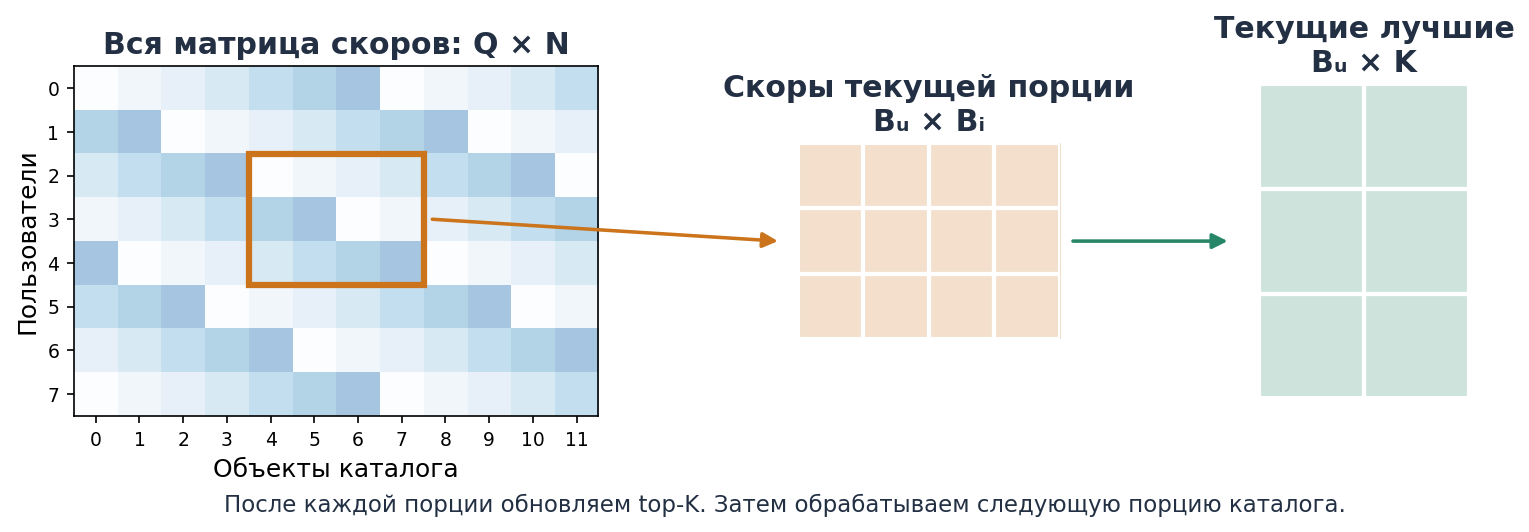

Оранжевая область — текущая порция скоров. Зелёная — лучшие ответы для той же группы пользователей.

Если $Q$ — число запросов, $N$ — размер каталога, а $d$ — размерность вектора,
память для скоров уменьшается с $O(QN)$ до $O(B_uB_i+B_uK)$.
Число вычислений остаётся $O(QNd)$.


In [68]:
def topk(scores, k):
    k = min(k, scores.shape[1])
    if k < 1:
        raise ValueError('topk requires a nonempty catalog and k >= 1')
    positions = np.argpartition(scores, scores.shape[1] - k, axis=1)[:, -k:]
    values = np.take_along_axis(scores, positions, axis=1)
    order = np.argsort(-values, axis=1)
    return (np.take_along_axis(values, order, axis=1),
            np.take_along_axis(positions, order, axis=1))


def ann_recall(found, truth):
    if len(found) != len(truth) or len(truth) == 0:
        raise ValueError('found and truth must contain the same nonzero number of queries')
    recalls = []
    for result, exact in zip(found, truth):
        exact = np.unique(exact[exact >= 0])
        if len(exact) == 0:
            raise ValueError('Each query must have at least one eligible exact neighbor')
        recalls.append(np.intersect1d(result[result >= 0], exact).size / len(exact))
    return float(np.mean(recalls))


def merge_topk(parts, k):
    scores = np.concatenate([part[0] for part in parts], axis=1)
    ids = np.concatenate([part[1] for part in parts], axis=1)
    scores = np.where(ids >= 0, scores, -np.inf)
    distances, positions = topk(scores, k)
    return distances, np.take_along_axis(ids, positions, axis=1)


def exact_topk(queries, items, k, user_block=32, item_block=32768):
    all_scores, all_ids = [], []
    for start in range(0, len(queries), user_block):
        block = queries[start:start + user_block]
        best = None
        for offset in range(0, len(items), item_block):
            scores, ids = topk(block @ items[offset:offset + item_block].T, k)
            part = (scores, ids + offset)
            best = part if best is None else merge_topk([best, part], k)
        all_scores.append(best[0])
        all_ids.append(best[1])
    return np.vstack(all_scores), np.vstack(all_ids)


Проверим блочный поиск на тех же запросах, что и полный перебор FAISS FlatIP.
Сравним найденные ID и скоры. Совпадение показывает, что обработка каталога порциями
не изменила задачу: мы получили точный top-K с меньшим объёмом промежуточных скоров.
Ответы FlatIP сохраним для оценки всех приближённых методов.


In [69]:
started = time.perf_counter()
flat_index = faiss.IndexFlatIP(dimension)
flat_index.add(item_factors)
flat_build_s = time.perf_counter() - started
exact_scores, exact_ids = flat_index.search(user_embeddings, TOP_K)
_, validation_exact_ids = flat_index.search(validation_queries, TOP_K)

numpy_rows = min(32, N_QUERIES)
numpy_scores, numpy_ids = exact_topk(user_embeddings[:numpy_rows], item_factors, TOP_K)
np.testing.assert_allclose(numpy_scores, exact_scores[:numpy_rows], rtol=1e-4, atol=1e-5)
assert ann_recall(numpy_ids, exact_ids[:numpy_rows]) > 0.999
print('Блочный поиск совпадает с FlatIP.')


Блочный поиск совпадает с FlatIP.


### Как сравниваем методы

Эталон — точный top-K из FlatIP на тех же нормированных векторах.
Для каждого пользователя считаем долю эталонных объектов в ответе и усредняем по запросам:

$$\operatorname{ANNRecall@K}=\frac{1}{Q}\sum_u\frac{|A_u\cap E_u|}{K}.$$

Здесь Aᵤ — найденные объекты, Eᵤ — точный top-K. Например, 99 общих объектов из 100
дают recall 99%. Порядок этих объектов не влияет на метрику. Это полнота поиска,
а не метрика отклика пользователей.

Параметры перебираем на validation. Среди конфигураций с recall ≥ 99% выбираем
минимальную p95 задержку одиночного запроса. Затем измеряем выбранную конфигурацию
на test. Если метод не достиг порога в проверенном диапазоне, он остаётся в таблице
настройки, но не попадает в итоговое сравнение при заданном качестве.

Перед замером прогреваем поиск. p50 и p95 считаем по одиночным запросам,
throughput — по батчу пользователей, беря медиану трёх запусков. Отдельно измеряем
время построения. Расчёт recall и подготовка данных не входят во время поиска.

В таблицах recall показан в процентах. Жирным выделены максимальные recall и throughput,
минимальные задержки и время построения.


In [70]:
def benchmark(search, queries, truth, label, family, build_s, repeats=3, latency_queries=64):
    search(queries[:min(8, len(queries))], truth.shape[1])
    batch_times = []
    for _ in range(repeats):
        started = time.perf_counter()
        _, ids = search(queries, truth.shape[1])
        batch_times.append(time.perf_counter() - started)
    latencies = []
    for query in queries[:latency_queries]:
        started = time.perf_counter()
        search(query[None, :], truth.shape[1])
        latencies.append((time.perf_counter() - started) * 1000)
    return {'method': label, 'family': family, 'ann_recall': ann_recall(ids, truth),
            'p50_ms': float(np.percentile(latencies, 50)),
            'p95_ms': float(np.percentile(latencies, 95)),
            'batch_qps': len(queries) / float(np.median(batch_times)), 'build_s': build_s}


def choose_setting(rows, target=0.99):
    eligible = [row for row in rows if row['ann_recall'] >= target]
    return min(eligible, key=lambda row: row['p95_ms']) if eligible else None


def build_ivf(items, train, nlist, seed, pq_m=None, nbits=8):
    quantizer = faiss.IndexFlatIP(items.shape[1])
    if pq_m is None:
        index = faiss.IndexIVFFlat(quantizer, items.shape[1], nlist, faiss.METRIC_INNER_PRODUCT)
    else:
        index = faiss.IndexIVFPQ(quantizer, items.shape[1], nlist, pq_m, nbits,
                                faiss.METRIC_INNER_PRODUCT)
        index.pq.cp.seed = seed
        index.pq.cp.niter = 15
    index.cp.seed = seed
    index.cp.niter = 15
    index.train(train)
    index.add(items)
    return index


def best_results(frame, group_by=None):
    maximize = {'ann_recall', 'candidate_recall', 'batch_qps'}
    minimize = {'p50_ms', 'p95_ms', 'build_s', 'wall_ms', 'MSE'}
    formatted = frame.copy()
    for column in frame.columns:
        values = frame[column]
        if column in maximize | minimize:
            operation = 'max' if column in maximize else 'min'
            best = getattr(values, operation)() if group_by is None else frame.groupby(group_by)[column].transform(operation)
            winners = np.isclose(values, best, rtol=1e-9, atol=1e-12)
            strings = []
            for value, winner in zip(values, winners):
                if pd.isna(value):
                    strings.append('—')
                    continue
                if column in {'ann_recall', 'candidate_recall'}:
                    text = f'{100 * value:.2f}%'
                elif column == 'MSE':
                    text = f'{value:.3e}'
                else:
                    text = f'{value:.3f}'
                strings.append(f'<b>{text}</b>' if winner else text)
            formatted[column] = strings
        else:
            formatted[column] = values.map(lambda value: '' if pd.isna(value) else escape(str(value)))
    formatted = formatted.drop(columns=['family'], errors='ignore')
    formatted = formatted.rename(columns={'method': 'Метод', 'ann_recall': 'ANN Recall@K',
        'candidate_recall': 'Candidate Recall@K', 'p50_ms': 'p50, мс', 'p95_ms': 'p95, мс',
        'batch_qps': 'Батч, запросов/с', 'build_s': 'Построение, с', 'wall_ms': 'Время, мс'})
    return HTML(formatted.to_html(index=False, escape=False))


Измерим FlatIP по этому протоколу. Его recall равен 1 по определению эталона.
Время поиска и размер индекса станут отправной точкой: следующие методы
должны дать выигрыш по времени при приемлемой потере соседей.


In [71]:
results = []
tuning_results = []
row = benchmark(flat_index.search, user_embeddings, exact_ids, 'FlatIP', 'Flat',
                flat_build_s, REPEATS, N_LATENCY_QUERIES)
row['validation_recall'] = 1.0
results.append(row)
display(best_results(pd.DataFrame(results).drop(columns=['validation_recall'])))


Метод,ANN Recall@K,"p50, мс","p95, мс","Батч, запросов/с","Построение, с"
FlatIP,100.00%,15.507,16.976,488.232,0.232


## 3. HNSW

Полный перебор сравнивает запрос со всем каталогом. HNSW заранее соединяет близкие
объекты в граф и при запросе проходит только его часть. На верхних разреженных уровнях
поиск быстро приближается к нужной области. На нижнем уровне рассматривает несколько
перспективных вершин и их соседей, уточняя ответ. За счёт пропущенных вершин поиск
ускоряется, но может потерять часть точного top-K.

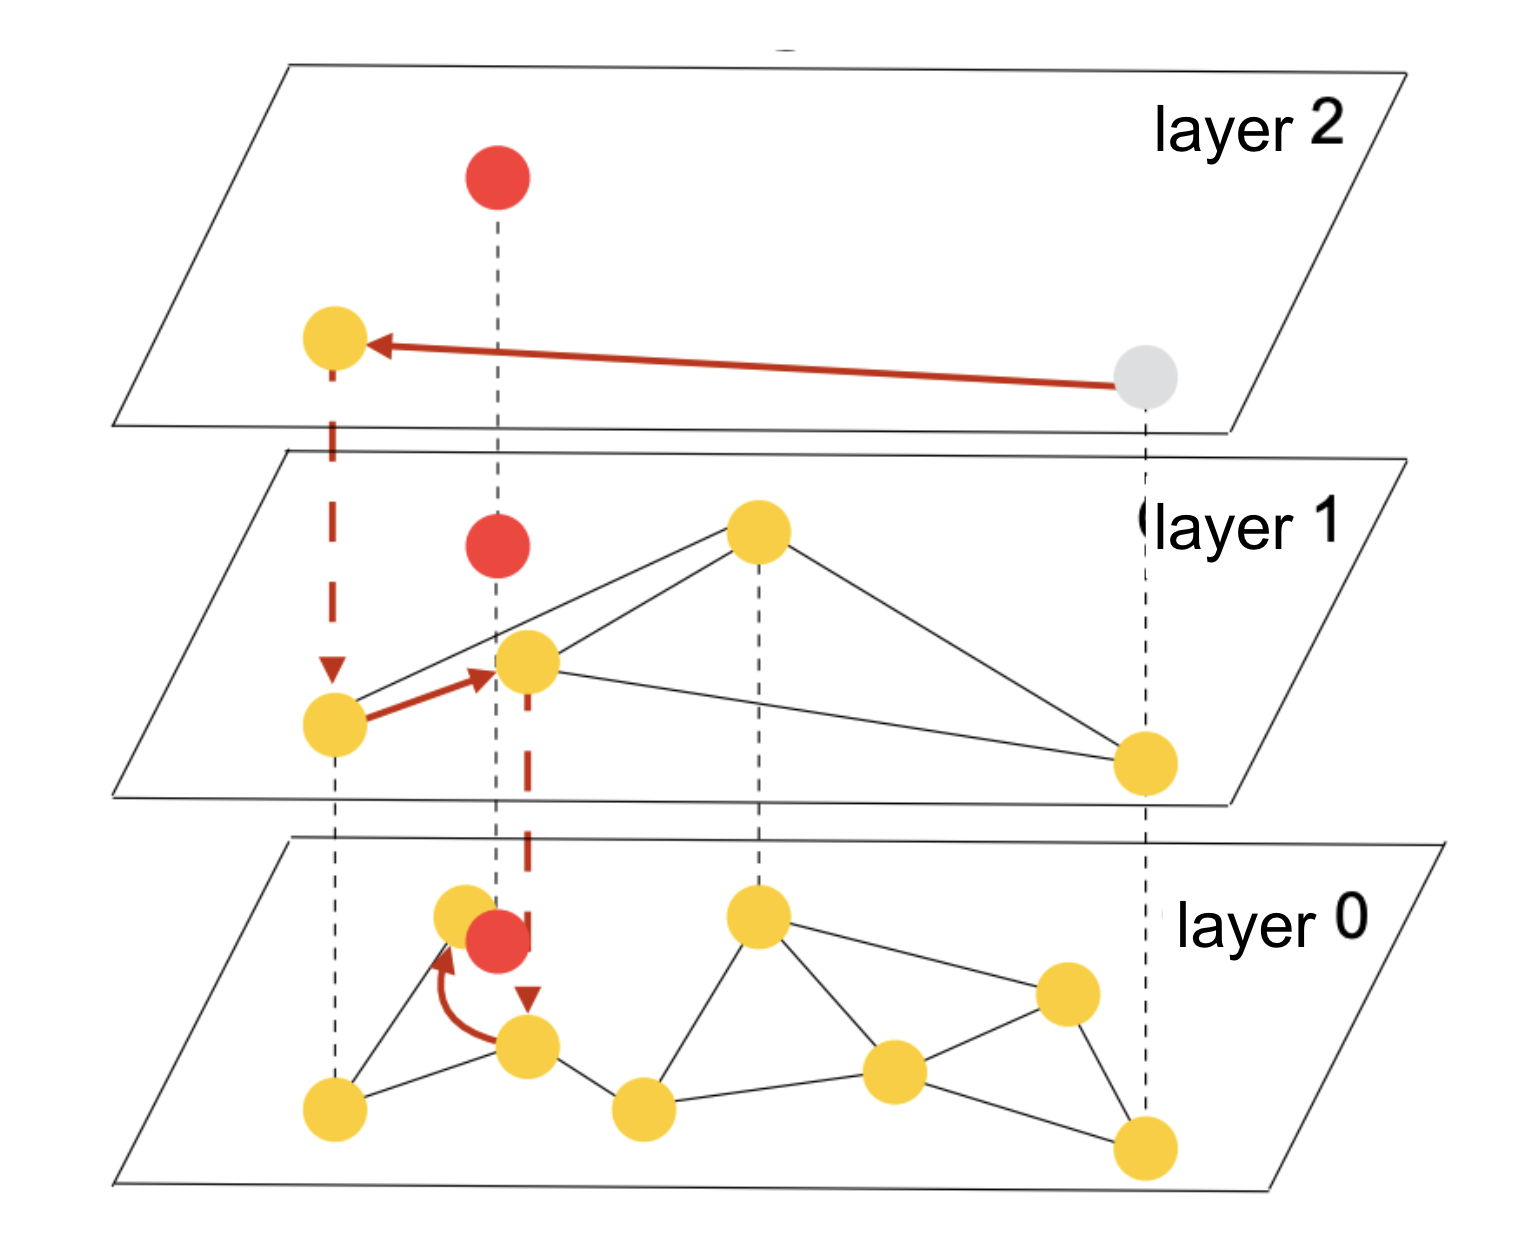

Красные стрелки показывают маршрут поиска и спуск между уровнями.

| Параметр | Что задаёт | Что меняется при увеличении |
|---|---|---|
| `M` | Число связей вершины: до M на верхних уровнях, до 2M на нижнем | Растут размер графа и стоимость построения; появляются дополнительные пути обхода |
| `efConstruction` | Ширину поиска соседей при добавлении объекта | Построение дольше, но найденные связи могут улучшить recall |
| `efSearch` | Размер множества кандидатов при обходе графа для запроса | Поиск дольше; обычно растёт recall |

`M` и `efConstruction` задаём перед добавлением объектов. Для их изменения
нужно перестроить граф. `efSearch` можно менять между запросами.
Это ширина поиска, а не точное число посещённых вершин.

На validation сравним графы M=16 и M=32 с efConstruction=80, а также
M=50 с efConstruction=1000. Для каждого проверим efSearch ∈ {128, 512, 1600}.
Конфигурация M=50, efConstruction=1000, efSearch=1600 служит проверкой высокой полноты.
Из достигших 99% выберем самую быструю и отдельно измерим её на test.


In [72]:
hnsw_indexes = {}
hnsw_tuning = []
for m, ef_construction in [(16, 80), (32, 80), (50, 1000)]:
    started = time.perf_counter()
    index = faiss.IndexHNSWFlat(dimension, m, faiss.METRIC_INNER_PRODUCT)
    index.hnsw.efConstruction = ef_construction
    index.add(item_factors)
    build_s = time.perf_counter() - started
    hnsw_indexes[(m, ef_construction)] = index
    for ef in [128, 512, 1600]:
        index.hnsw.efSearch = ef
        row = benchmark(index.search, validation_queries, validation_exact_ids,
                        f'HNSW M={m} ef={ef}', 'HNSW', build_s, REPEATS, N_LATENCY_QUERIES)
        row.update({'M': m, 'efConstruction': ef_construction, 'efSearch': ef})
        hnsw_tuning.append(row)
    print(f'HNSW M={m}, efConstruction={ef_construction}: построение {build_s:.2f} с')
display(best_results(pd.DataFrame(hnsw_tuning)))
tuning_results.extend(hnsw_tuning)

reference = next(row for row in hnsw_tuning if row['M'] == 50 and row['efSearch'] == 1600)
assert reference['ann_recall'] >= TARGET_RECALL, reference
chosen_hnsw = choose_setting(hnsw_tuning, TARGET_RECALL)
assert chosen_hnsw is not None
index = hnsw_indexes[(chosen_hnsw['M'], chosen_hnsw['efConstruction'])]
index.hnsw.efSearch = chosen_hnsw['efSearch']
row = benchmark(index.search, user_embeddings, exact_ids, chosen_hnsw['method'], 'HNSW',
                chosen_hnsw['build_s'], REPEATS, N_LATENCY_QUERIES)
row['validation_recall'] = chosen_hnsw['ann_recall']
results.append(row)
print(f"Выбрано по validation: {chosen_hnsw['method']}; test recall: {100 * row['ann_recall']:.3f}%")


HNSW M=16, efConstruction=80: построение 38.80 с
HNSW M=32, efConstruction=80: построение 39.24 с
HNSW M=50, efConstruction=1000: построение 524.20 с


Метод,ANN Recall@K,"p50, мс","p95, мс","Батч, запросов/с","Построение, с",M,efConstruction,efSearch
HNSW M=16 ef=128,86.94%,0.321,0.418,4576.092,38.797,16,80,128
HNSW M=16 ef=512,95.55%,0.964,1.215,1777.898,38.797,16,80,512
HNSW M=16 ef=1600,97.84%,3.578,4.369,477.645,38.797,16,80,1600
HNSW M=32 ef=128,87.28%,0.336,0.417,5774.995,39.243,32,80,128
HNSW M=32 ef=512,95.49%,0.987,1.247,1804.016,39.243,32,80,512
HNSW M=32 ef=1600,98.40%,3.531,4.151,492.244,39.243,32,80,1600
HNSW M=50 ef=128,97.11%,0.524,0.744,3318.523,524.197,50,1000,128
HNSW M=50 ef=512,99.63%,1.561,2.055,1038.615,524.197,50,1000,512
HNSW M=50 ef=1600,99.93%,5.134,6.283,311.874,524.197,50,1000,1600


Выбрано по validation: HNSW M=50 ef=512; test recall: 99.621%


## 4. IVF

IVF заранее делит каталог на группы. При обучении находит центроиды и относит
каждый объект к одному из них. При поиске сравнивает пользовательский вектор
с центроидами, выбирает несколько лучших по скалярному произведению и просматривает
только их списки объектов.

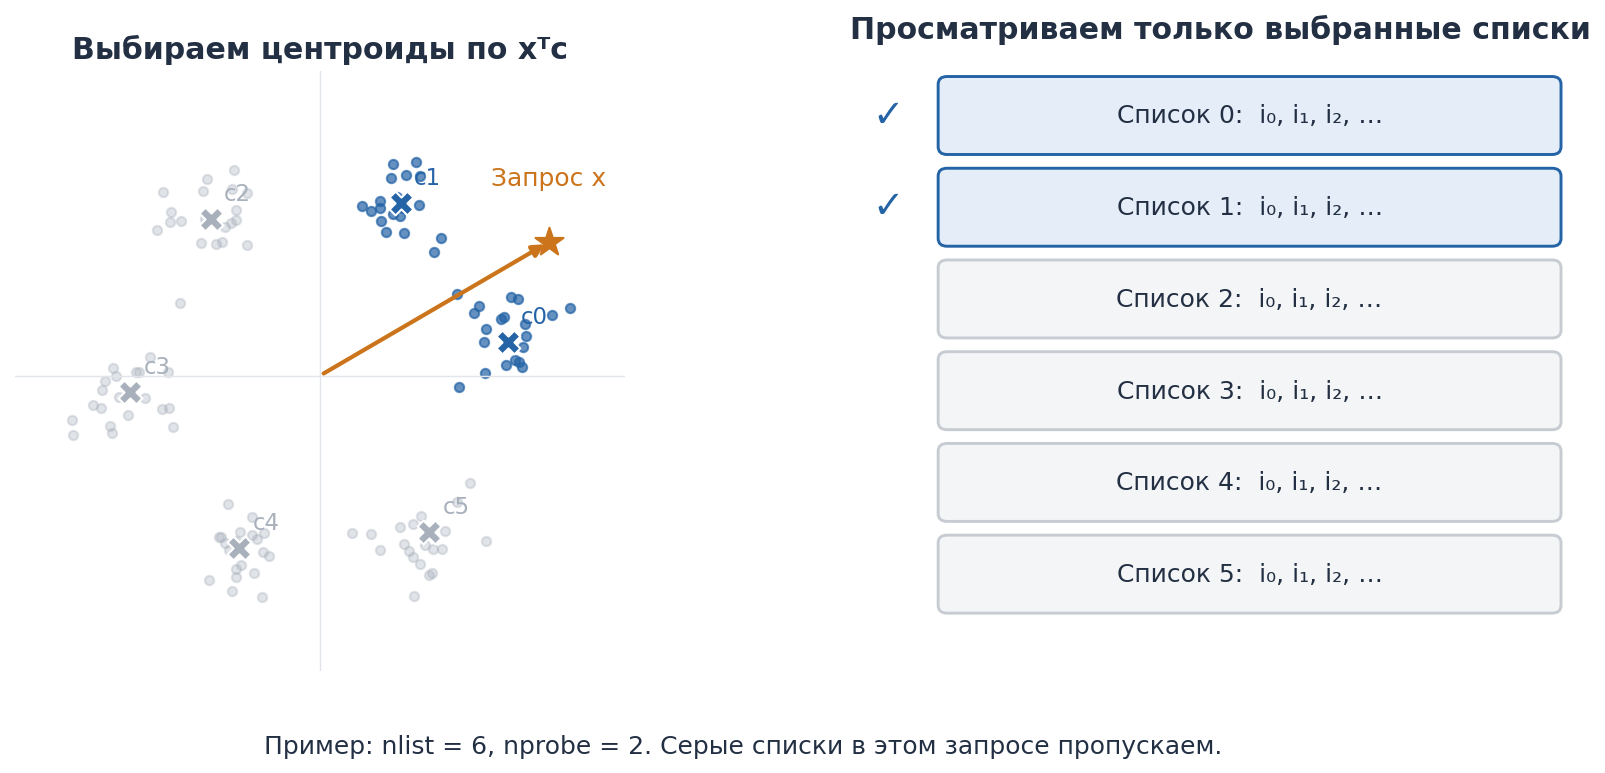

Синим выделены выбранные центроиды и их списки. В этом запросе просматриваем два списка из шести.

| Параметр | Что задаёт | Как влияет на поиск |
|---|---|---|
| `nlist` | Число кластеров при обучении | Больше кластеров — короче списки, но дороже выбор центроидов. Для обучения требуется больше данных |
| `nprobe` | Число списков, просматриваемых для запроса | Больше списков — больше проверенных объектов и выше время поиска |

При равных размерах списков проверяется примерно $N\cdot nprobe/nlist$ объектов.
Если списки несбалансированы, объём работы зависит от запроса.
В IVF-Flat выбранные объекты оцениваются исходными векторами, поэтому потери recall
возникают из-за пропущенных списков.

В основном опыте обучим один индекс с `nlist=256` за 15 итераций k-means. После этого сравним
`nprobe ∈ {8, 32, 128, 256}` без перестроения индекса. Увеличивая nprobe,
должны приближаться к полному перебору по качеству и по объёму вычислений.
Параметр выбираем на validation и проверяем выбранный вариант на test.
При nprobe=nlist отдельно проверим совпадение с FlatIP.

Изменение nlist требует переобучения индекса; nprobe выбирается при поиске.


In [73]:
started = time.perf_counter()
ivf_index = build_ivf(item_factors, train_items, NLIST, SEED)
ivf_build_s = time.perf_counter() - started
ivf_tuning = []
for nprobe in NPROBES:
    ivf_index.nprobe = nprobe
    row = benchmark(ivf_index.search, validation_queries, validation_exact_ids,
                    f'IVF-Flat nprobe={nprobe}', 'IVF-Flat', ivf_build_s, REPEATS, N_LATENCY_QUERIES)
    row['nprobe'] = nprobe
    ivf_tuning.append(row)
display(best_results(pd.DataFrame(ivf_tuning)))
tuning_results.extend(ivf_tuning)
ivf_index.nprobe = NLIST
_, exhaustive_ids = ivf_index.search(user_embeddings, TOP_K)
assert ann_recall(exhaustive_ids, exact_ids) > 0.999

chosen_ivf = choose_setting(ivf_tuning, TARGET_RECALL)
assert chosen_ivf is not None
ivf_index.nprobe = chosen_ivf['nprobe']
row = benchmark(ivf_index.search, user_embeddings, exact_ids, chosen_ivf['method'], 'IVF-Flat',
                ivf_build_s, REPEATS, N_LATENCY_QUERIES)
row['validation_recall'] = chosen_ivf['ann_recall']
results.append(row)


Метод,ANN Recall@K,"p50, мс","p95, мс","Батч, запросов/с","Построение, с",nprobe
IVF-Flat nprobe=8,89.71%,0.439,0.585,2750.325,3.913,8
IVF-Flat nprobe=32,97.09%,1.451,1.845,911.775,3.913,32
IVF-Flat nprobe=128,99.24%,7.401,8.856,168.398,3.913,128
IVF-Flat nprobe=256,100.00%,14.538,15.755,85.383,3.913,256


## 5. Скалярная квантизация

Заменим каждую координату float32 одним байтом. Код будет обозначать один из 256
уровней, а при деквантизации мы подставим значение этого уровня. Исходное число
в общем случае не восстановится точно.


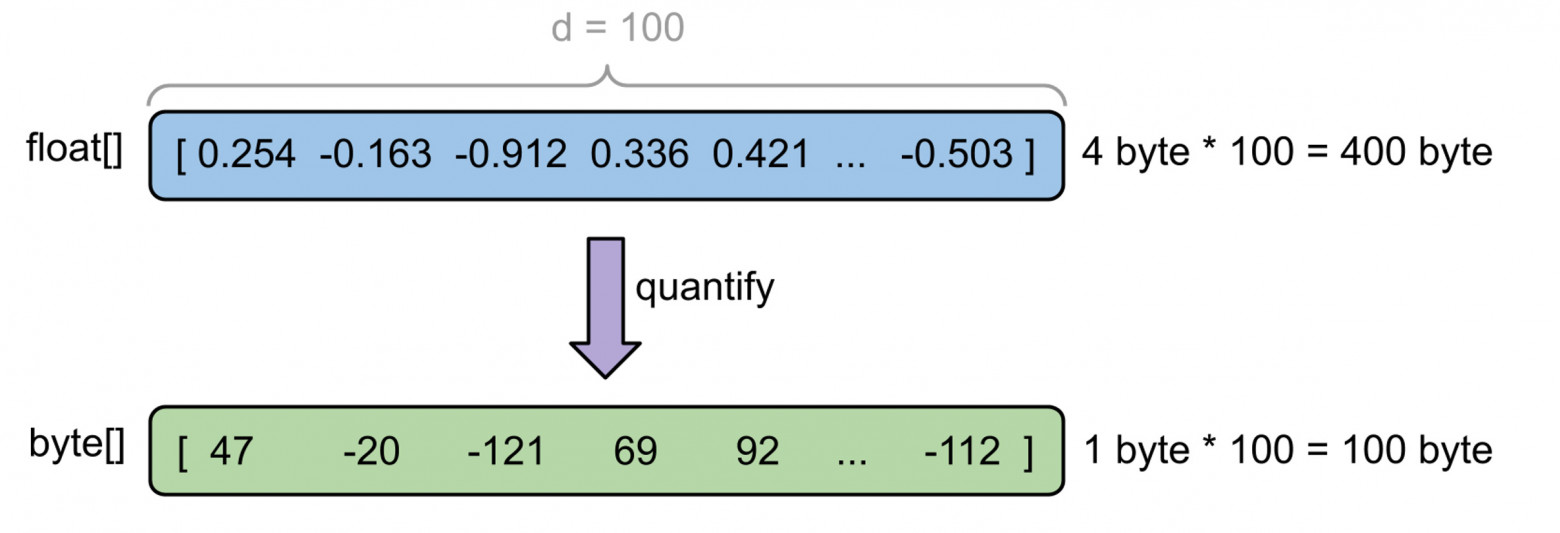

Каждая координата занимает один байт вместо четырёх.
На схеме показаны знаковые коды; ниже используем uint8 со значениями от 0 до 255.

### 5.1. Равномерные уровни: MinMax

Сначала выберем диапазон для каждой координаты, затем разместим в нём уровни
с одинаковым шагом. Координаты одного вектора могут иметь разные диапазоны.


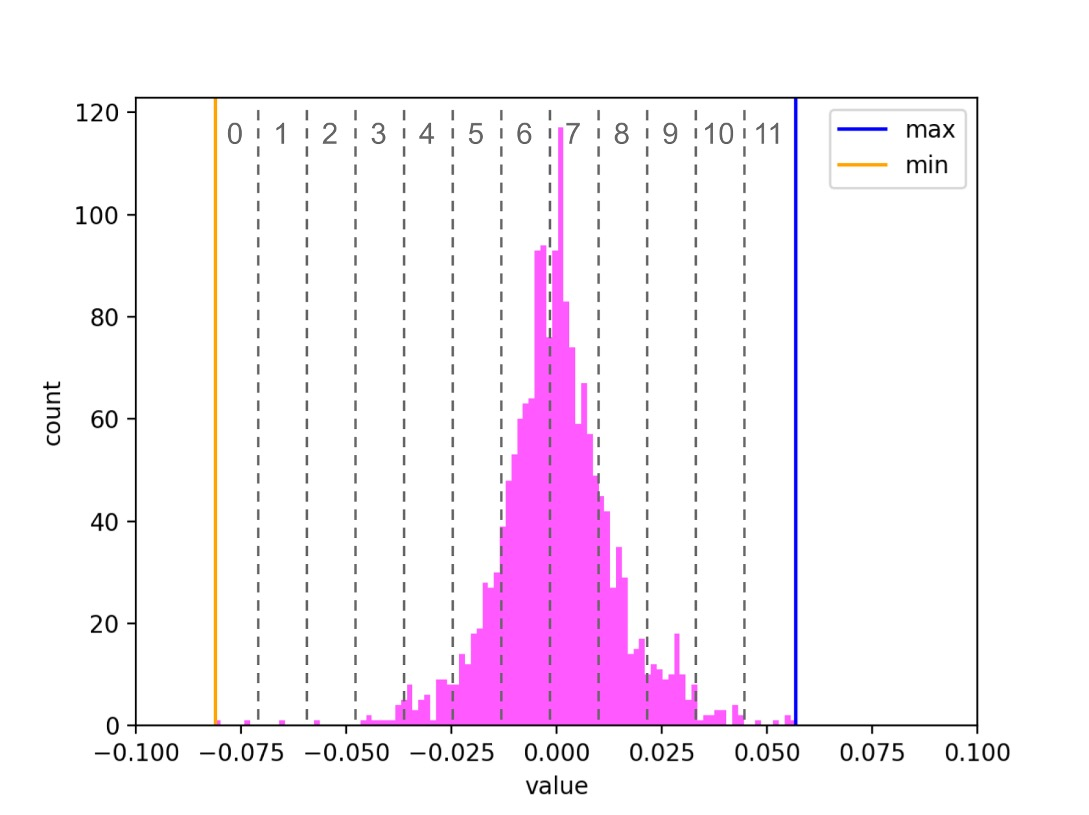

На рисунке показана равномерная сетка для одной координаты. Иллюстрация: [Евгений Харитонов, Яндекс](https://habr.com/ru/companies/yandex/articles/539960/).

**Подготовка по обучающей выборке**

1. Для координаты j найдём нижнюю и верхнюю границы. Возьмём 1-й и 99-й процентили:

$$l_j=P_{0.01}(y_j),\qquad h_j=P_{0.99}(y_j).$$

2. Рассчитаем расстояние между 256 уровнями:

$$\Delta_j=\frac{h_j-l_j}{255}.$$

3. Сохраним векторы границ l и h. Они общие для всех кодируемых объектов и нужны
при деквантизации.

Если использовать минимум и максимум, редкие выбросы могут растянуть сетку,
а основная масса значений попадёт в несколько центральных уровней.
Процентили сужают диапазон: точность внутри него растёт ценой обрезания хвостов.


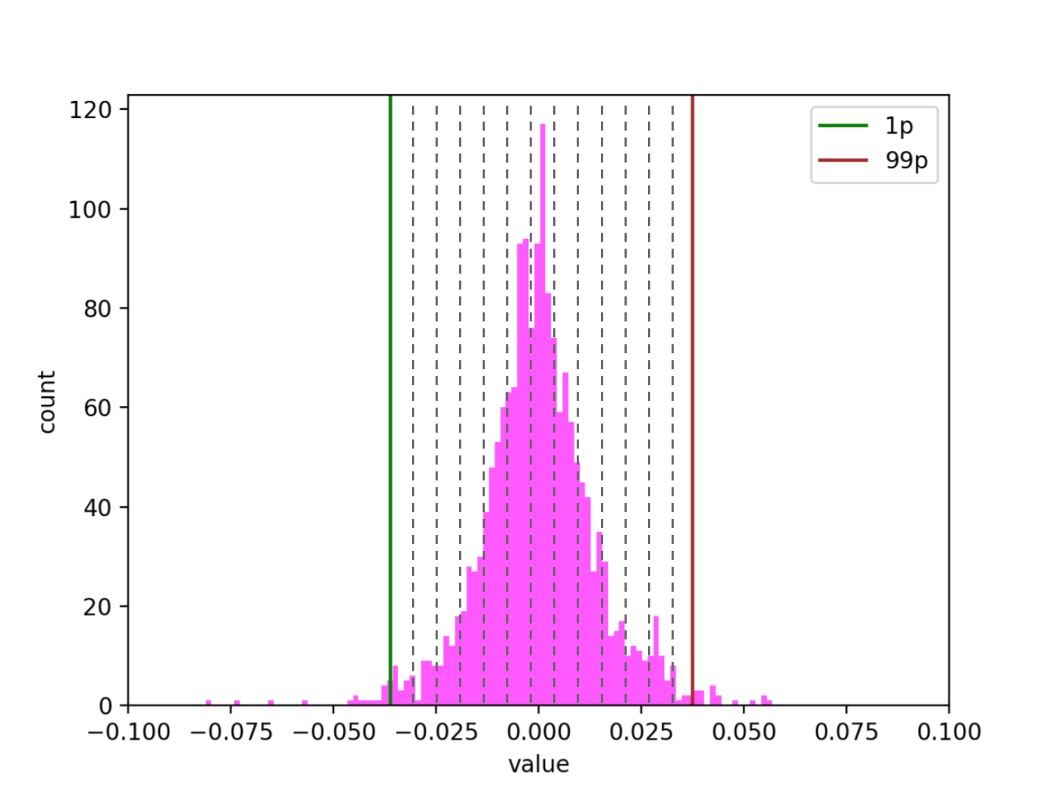

Равномерная сетка на диапазоне между 1-м и 99-м процентилями. Иллюстрация: [Яндекс](https://habr.com/ru/companies/yandex/articles/539960/).


**Квантование одного вектора y**

1. Обрежем каждую координату по сохранённым границам:

$$y'_j=\min\bigl(h_j,\max(l_j,y_j)\bigr).$$

2. Выразим её в шагах сетки и округлим до ближайшего целого:

$$q_j=\operatorname{round}\left(\frac{y'_j-l_j}{\Delta_j}\right),\qquad q_j\in\{0,\ldots,255\}.$$

3. Сохраним номера уровней как uint8. Для d координат получим d байт кодов.

**Деквантизация**

Для каждого кода возьмём нижнюю границу и добавим соответствующее число шагов:

$$\hat y_j=l_j+q_j\Delta_j.$$

Если $h_j=l_j$, координата постоянна: сохраняем код 0 и восстанавливаем l_j.

Например, при l=-1, h=1 и y=0.25 шаг равен 2/255. Получим q=159,
а после деквантизации — -1 + 159·2/255 ≈ 0.2471. Небольшая ошибка возникла
из-за округления к уровню сетки.

Ниже реализуем эти два преобразования. Затем применим их ко всему каталогу
и сравним рекомендации до и после сжатия.


In [74]:
def scalar_quantize(values, low, high):
    span = np.where(high > low, high - low, 1.0)
    clipped = np.clip(values, low, high)
    scaled = (clipped - low) / span
    return np.rint(scaled * 255).astype(np.uint8)


def scalar_restore(codes, low, high):
    return (codes.astype(np.float32) / 255 * (high - low) + low).astype(np.float32)

Оценим границы по обучающим векторам объектов, сожмём каталог и восстановим его в FP32.
Запросы останутся теми же нормированными пользовательскими векторами.
Повторим FlatIP-поиск и измерим, как ошибка кодирования изменила top-K.

MSE описывает ошибку координат и не является процентом качества. ANN Recall показывает
долю сохранённых соседей. На графике восстановленные координаты сравниваются с исходными:
чем ближе точка к диагонали, тем меньше ошибка её восстановления.


SQ8 ANN Recall@100: 89.176%
MSE: 2.9490835004253313e-05


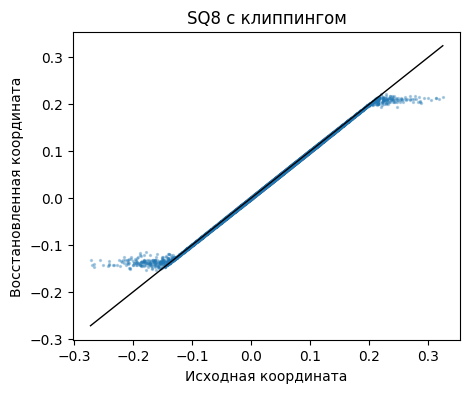

In [75]:
low = np.percentile(train_items, 1, axis=0).astype(np.float32)
high = np.percentile(train_items, 99, axis=0).astype(np.float32)
scalar_codes = scalar_quantize(item_factors, low, high)
restored_items = scalar_restore(scalar_codes, low, high)
scalar_index = faiss.IndexFlatIP(dimension)
scalar_index.add(restored_items)
_, scalar_ids = scalar_index.search(user_embeddings, TOP_K)
print(f'SQ8 ANN Recall@{TOP_K}: {100 * ann_recall(scalar_ids, exact_ids):.3f}%')
print('MSE:', float(np.mean((item_factors - restored_items)**2)))
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(item_factors[:100].ravel(), restored_items[:100].ravel(), s=2, alpha=0.3)
limits = [float(item_factors[:100].min()), float(item_factors[:100].max())]
ax.plot(limits, limits, color='black', linewidth=1)
ax.set(xlabel='Исходная координата', ylabel='Восстановленная координата', title='SQ8 с клиппингом')
plt.show()
del scalar_index, restored_items
gc.collect();


### 5.2. Квантильные интервалы

Равномерная сетка тратит столько же уровней на редкие значения, сколько на плотную
область той же ширины. Попробуем поставить больше границ там, где больше значений.

**Подготовка**

Для каждой координаты j найдём 257 границ. Сохраним тот же диапазон от 1-го
до 99-го процентиля, но внутренние границы разместим по квантилям:

$$t_{j,r}=P_{\,0.01+0.98r/256}(y_j),\qquad r=0,\ldots,256.$$

Между границами получаются 256 интервалов с примерно одинаковым числом обучающих значений.
В плотных областях интервалы узкие, в разрежённых — широкие.

**Квантование**

1. Обрежем координату по крайним границам.
2. Найдём интервал, в который она попала, и сохраним его номер q_j как uint8:

$$t_{j,q_j}\le y'_j<t_{j,q_j+1}.$$

Правая граница последнего интервала включается в него. При совпадающих границах
часть интервалов пустая; у постоянной координаты сохраняем код 0.

**Деквантизация**

По номеру интервала восстановим его середину:

$$\hat y_j=\frac{t_{j,q_j}+t_{j,q_j+1}}{2}.$$

Например, значение -0.07 попадает в интервал [-0.10, 0.00) и восстанавливается
как -0.05. Теперь для деквантизации нужны все границы, а не только l и h.


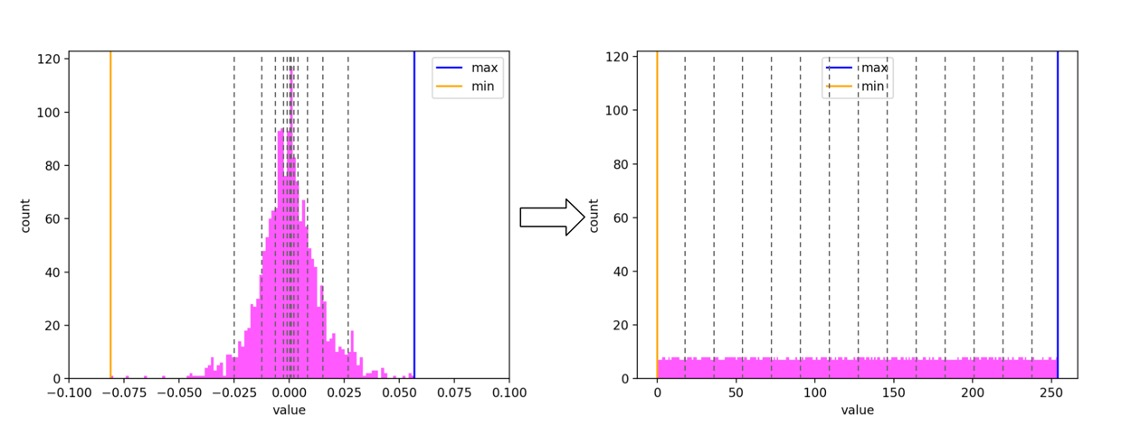

В плотной области границы стоят чаще. Справа — распределение номеров интервалов.
Иллюстрация: [Евгений Харитонов, Яндекс](https://habr.com/ru/companies/yandex/articles/539960/).


In [76]:
def fit_quantile_edges(values, levels=256):
    if not 2 <= levels <= 256:
        raise ValueError('levels must be between 2 and 256 for uint8 codes')
    return np.quantile(values, np.linspace(0.01, 0.99, levels + 1), axis=0).astype(np.float32)


def quantile_quantize(values, edges):
    codes = np.zeros(values.shape, dtype=np.uint8)
    for j in range(values.shape[1]):
        if edges[-1, j] > edges[0, j]:
            clipped = np.clip(values[:, j], edges[0, j], edges[-1, j])
            codes[:, j] = np.searchsorted(edges[1:-1, j], clipped, side='right')
    return codes


def quantile_restore(codes, edges):
    centers = (edges[:-1] + edges[1:]) / 2
    return centers[codes, np.arange(codes.shape[1])].astype(np.float32)


Сравним MinMax и квантильную сетку на одной обучающей выборке с теми же крайними процентилями.
Для каждого метода сожмём каталог, восстановим координаты и выполним поиск по тем же запросам.
В таблице приведены ANN Recall и MSE. Далее PQ позволит искать непосредственно по кодам.


In [77]:
quantile_edges = fit_quantile_edges(train_items)
scalar_comparison = []
for method in ['SQ8 MinMax', 'SQ8 quantiles']:
    if method == 'SQ8 MinMax':
        codes = scalar_quantize(item_factors, low, high)
        reconstructed = scalar_restore(codes, low, high)
    else:
        codes = quantile_quantize(item_factors, quantile_edges)
        reconstructed = quantile_restore(codes, quantile_edges)
    index = faiss.IndexFlatIP(dimension)
    index.add(reconstructed)
    _, found = index.search(user_embeddings, TOP_K)
    scalar_comparison.append({'method': method, 'ann_recall': ann_recall(found, exact_ids),
                              'MSE': float(np.mean((item_factors - reconstructed)**2))})
    del index, reconstructed, codes
    gc.collect()
scalar_comparison = pd.DataFrame(scalar_comparison)
display(best_results(scalar_comparison))
scalar_comparison.to_csv(ARTIFACT_DIR / 'scalar_quantization_results.csv', index=False)


Метод,ANN Recall@K,MSE
SQ8 MinMax,89.18%,2.949e-05
SQ8 quantiles,88.08%,3.601e-05


## 6. Product Quantization

PQ кодирует сразу группы координат. Разобьём вектор размерности d на m частей,
каждую заменим номером близкого подвектора из заранее обученного codebook-а.
Для восстановления кода нужны сами codebook-и.

**Обучение codebook-ов**

1. Разделим каждый обучающий вектор на m частей размерности d/m:

$$y=\bigl[y^{(1)},\ldots,y^{(m)}\bigr].$$

2. Для каждой позиции j соберём соответствующие части всех обучающих векторов.
3. Обучим на них k-means с 2ᵇ центроидами. Получим отдельную книгу для каждой позиции:

$$C_j=\{c_{j,0},\ldots,c_{j,2^b-1}\}.$$

**Квантование**

Для каждой части объекта найдём ближайший центроид по L2 и сохраним его номер:

$$q_j=\arg\min_{0\le r<2^b}\left\|y^{(j)}-c_{j,r}\right\|_2^2.$$

Весь код объекта — последовательность m номеров: q=(q₁,…,qₘ).

**Деквантизация**

Прочитаем центроид по каждому номеру и соединим полученные части:

$$\hat y=\bigl[c_{1,q_1},\ldots,c_{m,q_m}\bigr].$$


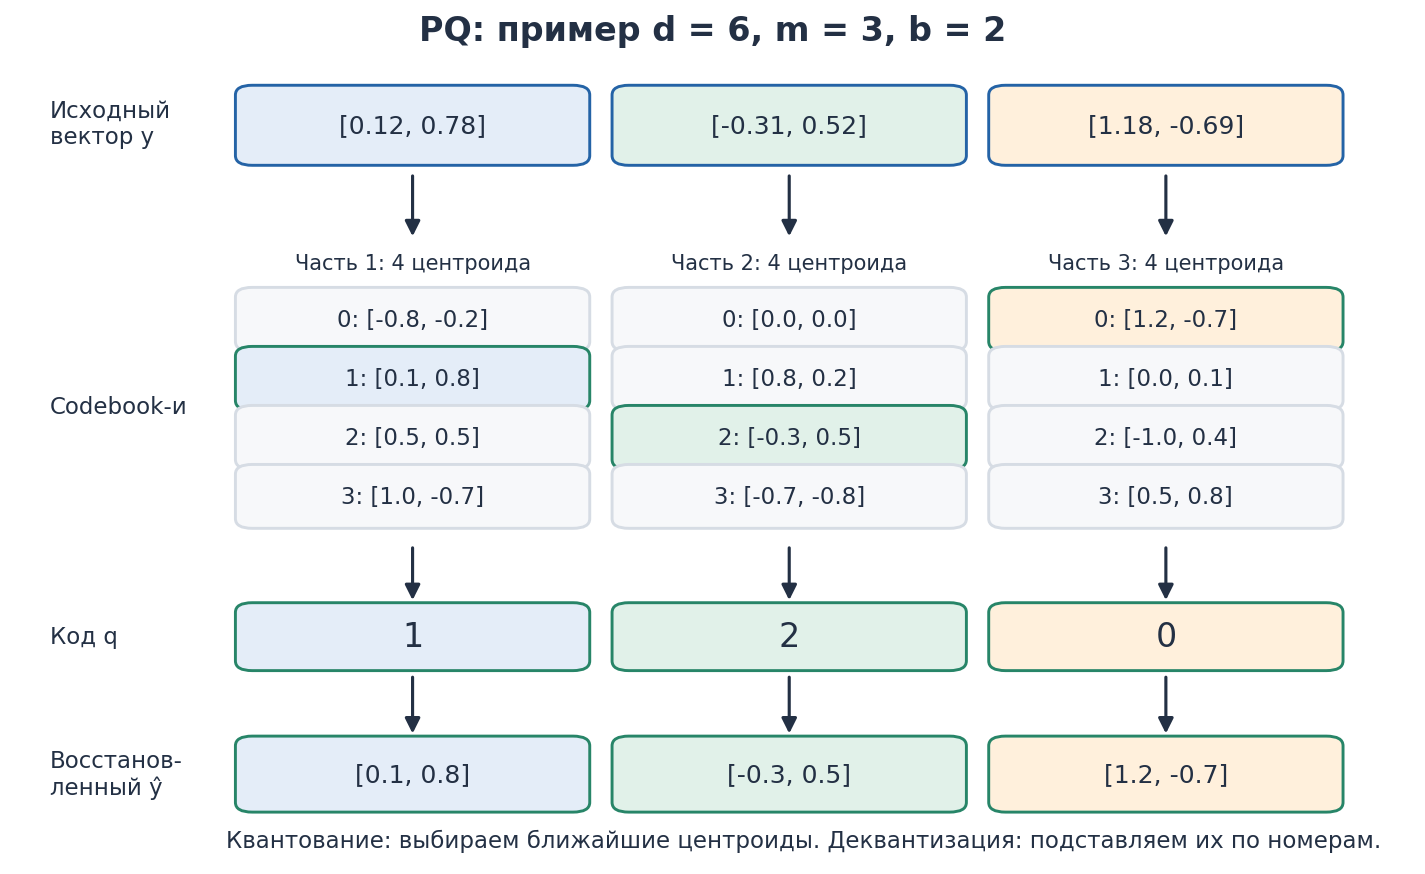


В примере каждая часть имеет четыре центроида. Код [1, 2, 0] восстанавливается
в [0.1, 0.8, -0.3, 0.5, 1.2, -0.7]. Выделенные строки — выбранные центроиды.

| Параметр | Что задаёт | Что меняется при увеличении |
|---|---|---|
| `m` | Число частей вектора; размерность каждой части равна d/m | Код длиннее, части меньше; обычно уменьшается ошибка восстановления, но требуется больше сложений при поиске |
| `nbits` (b) | Число бит на номер центроида в каждой части | Больше уровней квантования и длиннее код; число центроидов и размер таблиц растут как 2ᵇ |

В этой реализации d должно делиться на m. Код занимает ⌈mb/8⌉ байт,
а codebook-и в FP32 занимают 2ᵇ·d·4 байт. При d=128, m=16, b=8 получаются 16 частей
по 8 координат. Каждая часть кодируется байтом: 16 байт на объект вместо 512.

**Поиск по кодам без восстановления каталога**

1. Разделим запрос x на те же m частей.
2. Для каждой части посчитаем произведения со всеми центроидами:

$$T_{j,r}=\left(x^{(j)}\right)^T c_{j,r}.$$

3. Для объекта прочитаем m значений из таблиц по его коду и сложим:

$$\hat s(x,y)=\sum_{j=1}^{m}T_{j,q_j}.$$

IndexPQ просматривает коды всего каталога. Сравним m ∈ {16, 32, 64} при nbits=8 на validation:
какой выигрыш по качеству даёт более длинный код и сколько он стоит по памяти и времени.

### IVF-PQ

Объединим отбор списков IVF со сжатием PQ. При построении для объекта выбирается
список с центроидом cℓ, а PQ кодирует остаток r=y−cℓ. Восстановленный объект:

$$\hat y=c_\ell+\bigl[c_{1,q_1},\ldots,c_{m,q_m}\bigr].$$

При запросе сначала выберем nprobe списков, затем посчитаем приближённые скоры
их объектов по кодам. Фиксируем m=32, nbits=8 и меняем nprobe на validation.
Потери могут возникать из-за пропущенных списков и ошибок восстановления.


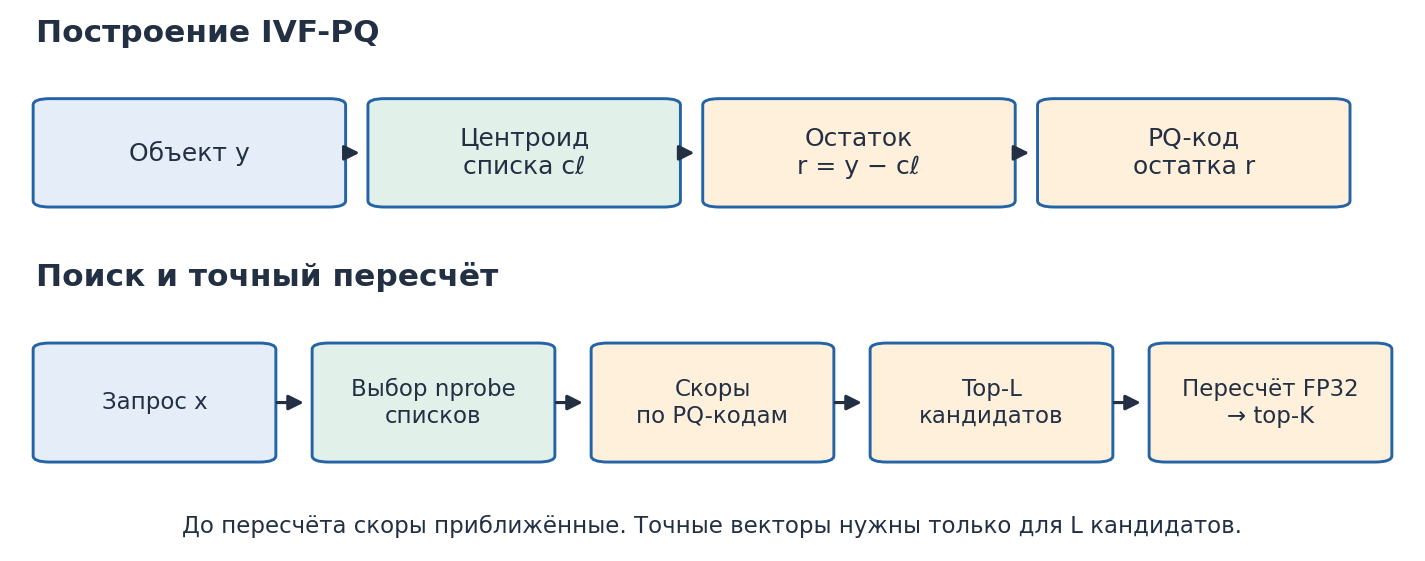


На нижней схеме показан также точный пересчёт top-L, который разберём в следующем разделе.

Изменение m или nbits требует переобучения codebook-ов. Обучаем их за 15 итераций
k-means, минимизирующего ошибку восстановления L2. Качество top-K по скалярному
произведению проверяем отдельно.


In [78]:
pq_indexes = {}
pq_tuning = []
for m in [16, 32, 64]:
    assert dimension % m == 0
    started = time.perf_counter()
    index = faiss.IndexPQ(dimension, m, 8, faiss.METRIC_INNER_PRODUCT)
    index.pq.cp.seed = SEED
    index.pq.cp.niter = 15
    index.train(train_items)
    index.add(item_factors)
    build_s = time.perf_counter() - started
    pq_indexes[m] = index
    row = benchmark(index.search, validation_queries, validation_exact_ids,
                    f'PQ m={m}', 'PQ', build_s, REPEATS, N_LATENCY_QUERIES)
    row.update({'m': m, 'code_bytes_per_vector': index.code_size})
    pq_tuning.append(row)
display(best_results(pd.DataFrame(pq_tuning)))
tuning_results.extend(pq_tuning)
chosen_pq = choose_setting(pq_tuning, TARGET_RECALL)
if chosen_pq is not None:
    row = benchmark(pq_indexes[chosen_pq['m']].search, user_embeddings, exact_ids,
                    chosen_pq['method'], 'PQ', chosen_pq['build_s'], REPEATS, N_LATENCY_QUERIES)
    row['validation_recall'] = chosen_pq['ann_recall']
    results.append(row)

started = time.perf_counter()
ivfpq_index = build_ivf(item_factors, train_items, NLIST, SEED, pq_m=32)
ivfpq_build_s = time.perf_counter() - started
ivfpq_tuning = []
for nprobe in NPROBES:
    ivfpq_index.nprobe = nprobe
    row = benchmark(ivfpq_index.search, validation_queries, validation_exact_ids,
                    f'IVF-PQ nprobe={nprobe}', 'IVF-PQ', ivfpq_build_s, REPEATS, N_LATENCY_QUERIES)
    row['nprobe'] = nprobe
    ivfpq_tuning.append(row)
display(best_results(pd.DataFrame(ivfpq_tuning)))
tuning_results.extend(ivfpq_tuning)
chosen_ivfpq = choose_setting(ivfpq_tuning, TARGET_RECALL)
if chosen_ivfpq is not None:
    ivfpq_index.nprobe = chosen_ivfpq['nprobe']
    row = benchmark(ivfpq_index.search, user_embeddings, exact_ids, chosen_ivfpq['method'],
                    'IVF-PQ', ivfpq_build_s, REPEATS, N_LATENCY_QUERIES)
    row['validation_recall'] = chosen_ivfpq['ann_recall']
    results.append(row)


Метод,ANN Recall@K,"p50, мс","p95, мс","Батч, запросов/с","Построение, с",m,code_bytes_per_vector
PQ m=16,51.42%,14.414,34.942,250.568,4.338,16,16
PQ m=32,74.31%,4.815,5.449,172.213,7.037,32,32
PQ m=64,91.05%,19.001,21.902,77.931,10.638,64,64


Метод,ANN Recall@K,"p50, мс","p95, мс","Батч, запросов/с","Построение, с",nprobe
IVF-PQ nprobe=8,75.98%,0.515,0.694,3068.329,9.299,8
IVF-PQ nprobe=32,78.86%,1.845,2.494,840.079,9.299,32
IVF-PQ nprobe=128,79.26%,10.108,11.636,164.771,9.299,128
IVF-PQ nprobe=256,79.30%,16.865,18.274,68.326,9.299,256


## 7. Пересчёт кандидатов

Приближённый поиск может найти нужный объект, но занизить его скор и поставить
ниже границы top-K. Попробуем сначала запросить больше объектов — top-L, — а затем
пересчитать их скоры по исходным векторам и оставить K лучших.

Например, для выдачи из 100 объектов найдём 1000 кандидатов. Точные произведения
посчитаем только для этой тысячи вместо всего каталога. Такой пересчёт исправляет
порядок кандидатов, но не может вернуть объекты, пропущенные первым этапом.

В следующей функции реализуем второй этап: для каждого пользователя оценим
найденных кандидатов исходными векторами и выберем top-K.


In [79]:
def rerank_candidates(queries, items, candidates, k, block_size=32):
    scores_out, ids_out = [], []
    for start in range(0, len(queries), block_size):
        ids = candidates[start:start + block_size]
        vectors = items[np.maximum(ids, 0)]
        scores = np.einsum('qd,qld->ql', queries[start:start + block_size], vectors)
        scores = np.where(ids >= 0, scores, -np.inf)
        distances, positions = topk(scores, k)
        scores_out.append(distances)
        ids_out.append(np.take_along_axis(ids, positions, axis=1))
    return np.vstack(scores_out), np.vstack(ids_out)


Зафиксируем nprobe=128 и на validation сравним L ∈ {100, 300, 1000, 3000, 10000} при K=100.
Чем больше L, тем больше объектов получат точные скоры, но тем дольше пересчёт.
Из вариантов с recall ≥ 99% выберем минимальную p95 задержку и проверим его на test.

Candidate recall — доля точного top-K, попавшая в top-L первого этапа. После пересчёта
тем же скалярным произведением она должна совпасть с итоговым ANN Recall:
найденные эталонные объекты сохраняются в ответе. Время включает оба этапа.


In [80]:
ivfpq_index.nprobe = min(128, NLIST)
rerank_tuning = []
for candidate_limit in [100, 300, 1000, 3000, 10000]:
    candidate_limit = min(candidate_limit, n_items)
    _, candidate_ids = ivfpq_index.search(validation_queries, candidate_limit)
    candidate_recall = ann_recall(candidate_ids, validation_exact_ids)

    def search_with_rerank(queries, k, limit=candidate_limit):
        _, candidates = ivfpq_index.search(queries, limit)
        return rerank_candidates(queries, item_factors, candidates, k)

    row = benchmark(search_with_rerank, validation_queries, validation_exact_ids,
                    f'IVF-PQ + rerank L={candidate_limit}', 'IVF-PQ + rerank',
                    ivfpq_build_s, REPEATS, N_LATENCY_QUERIES)
    row.update({'L': candidate_limit, 'candidate_recall': candidate_recall})
    assert abs(row['ann_recall'] - candidate_recall) < 0.001
    rerank_tuning.append(row)
display(best_results(pd.DataFrame(rerank_tuning)))
tuning_results.extend(rerank_tuning)

chosen_rerank = choose_setting(rerank_tuning, TARGET_RECALL)
assert chosen_rerank is not None, 'Increase candidate depth on validation before evaluating test'
candidate_limit = chosen_rerank['L']
def selected_rerank(queries, k):
    _, candidates = ivfpq_index.search(queries, candidate_limit)
    return rerank_candidates(queries, item_factors, candidates, k)
row = benchmark(selected_rerank, user_embeddings, exact_ids, chosen_rerank['method'],
                'IVF-PQ + rerank', ivfpq_build_s, REPEATS, N_LATENCY_QUERIES)
_, candidates = ivfpq_index.search(user_embeddings, candidate_limit)
row['candidate_recall'] = ann_recall(candidates, exact_ids)
row['validation_recall'] = chosen_rerank['ann_recall']
assert abs(row['ann_recall'] - row['candidate_recall']) < 0.001
results.append(row)


Метод,ANN Recall@K,"p50, мс","p95, мс","Батч, запросов/с","Построение, с",L,Candidate Recall@K
IVF-PQ + rerank L=100,79.26%,8.858,10.626,163.427,9.299,100,79.26%
IVF-PQ + rerank L=300,97.60%,8.961,9.894,105.893,9.299,300,97.60%
IVF-PQ + rerank L=1000,99.19%,9.301,10.349,149.288,9.299,1000,99.19%
IVF-PQ + rerank L=3000,99.23%,10.183,12.041,132.930,9.299,3000,99.23%
IVF-PQ + rerank L=10000,99.24%,14.606,17.226,82.369,9.299,10000,99.24%


## 8. Шардирование

В блочном поиске порции каталога ограничивали память одного поиска.
Теперь для каждой части каталога построим отдельный индекс — шард.
Один запрос отправим во все индексы; их можно обрабатывать одновременно.

Каждый шард вернёт свой top-K. Координатор объединит ответы и выберет глобальный
top-K по скорам. Для двух шардов и K=100 координатору достаточно обработать
не более 200 кандидатов. Скоры сравнимы: везде используются те же векторы и метрика.

Для точного поиска локальных K достаточно. Если объект не вошёл в top-K своего
шарда, у него уже есть K лучших конкурентов, поэтому он не попадёт и в глобальный top-K.

Ниже определим построение шардов и два способа обращения к ним:
последовательный и параллельный. При объединении учтём, что номера объектов
внутри каждого индекса локальные, а в итоговом ответе нужны номера общего каталога.


In [81]:
def build_shards(items, n_shards, kind='flat'):
    if not 1 <= n_shards <= len(items):
        raise ValueError('n_shards must be between 1 and catalog size')
    if kind != 'flat':
        raise ValueError('This experiment uses exact FlatIP shards')
    shards = []
    offset = 0
    for block in np.array_split(items, n_shards):
        index = faiss.IndexFlatIP(items.shape[1])
        index.add(np.ascontiguousarray(block))
        shards.append((index, offset))
        offset += len(block)
    return shards


def search_shards(shards, queries, k, parallel=False, delays=None):
    previous_threads = faiss.omp_get_max_threads()
    delays = {} if delays is None else delays
    def search_one(number):
        faiss.omp_set_num_threads(1)
        if delays.get(number, 0):
            time.sleep(delays[number])
        index, offset = shards[number]
        distances, ids = index.search(queries, k)
        return distances, np.where(ids >= 0, ids + offset, -1)
    try:
        if parallel:
            with ThreadPoolExecutor(max_workers=len(shards)) as pool:
                parts = list(pool.map(search_one, range(len(shards))))
        else:
            parts = [search_one(number) for number in range(len(shards))]
        return merge_topk(parts, k)
    finally:
        faiss.omp_set_num_threads(previous_threads)


Разделим каталог на 1, 2 и 4 шарда FlatIP. Для каждого разбиения сравним последовательный
и параллельный поиск на test-запросах. Каждый шард использует один поток FAISS;
в параллельном варианте несколько обработчиков работают одновременно.

Recall должен остаться 100%: разбиение и объединение ответов не меняют точный top-K.
Время включает создание пула и объединение результатов. Все индексы находятся в одном процессе.


In [82]:
shard_rows = []
for n_shards in [1, 2, 4]:
    started = time.perf_counter()
    shards = build_shards(item_factors, n_shards)
    build_s = time.perf_counter() - started
    for parallel in ([False] if n_shards == 1 else [False, True]):
        def search(queries, k, current=shards, concurrent=parallel):
            return search_shards(current, queries, k, parallel=concurrent)
        label = f'FlatIP shards={n_shards} ' + ('parallel' if parallel else 'sequential')
        row = benchmark(search, user_embeddings, exact_ids, label, 'Sharded FlatIP',
                        build_s, REPEATS, N_LATENCY_QUERIES)
        row.update({'n_shards': n_shards, 'parallel': parallel})
        assert row['ann_recall'] > 0.999
        shard_rows.append(row)
shard_table = pd.DataFrame(shard_rows)
display(best_results(shard_table))


Метод,ANN Recall@K,"p50, мс","p95, мс","Батч, запросов/с","Построение, с",n_shards,parallel
FlatIP shards=1 sequential,100.00%,13.831,15.991,597.618,0.134,1,False
FlatIP shards=2 sequential,100.00%,14.078,15.300,590.633,0.154,2,False
FlatIP shards=2 parallel,100.00%,17.658,21.400,630.178,0.154,2,True
FlatIP shards=4 sequential,100.00%,14.046,15.387,317.251,0.153,4,False
FlatIP shards=4 parallel,100.00%,13.172,15.155,614.027,0.153,4,True


### Медленный шард

Параллельные запросы заканчиваются в разное время. Если для полной выдачи нужны
ответы всех шардов, один задержавшийся шард задержит весь запрос.
При времени ответа шарда $t_s$ последовательный обход занимает примерно
$\sum_s t_s$, параллельный — $\max_s t_s$ плюс время объединения.

Проверим это на четырёх точных индексах. В первом случае добавим к каждому
обращению задержку 10 мс. Во втором оставим три задержки по 10 мс, а последнюю
увеличим до 80 мс. Эти паузы имитируют ожидание сети, CPU или диска.

Только добавленные паузы во втором случае дадут 110 мс при последовательном
обходе и около 80 мс при параллельном. К ним прибавятся поиск и объединение.
По таблице проверим, насколько один медленный ответ уменьшил выигрыш от параллелизма.

Здесь ждём все шарды, поэтому recall должен остаться равным 1. Если вместо этого
вернуть ответ по дедлайну, не дождавшись медленного шарда, его кандидаты потеряются.
Именно такой выбор между временем ответа и полнотой возникает при обслуживании запросов.


In [83]:
demo_shards = build_shards(item_factors, 4, 'flat')
slow_rows = []
for scenario, delays in [('equal synthetic delay', {i: 0.01 for i in range(4)}),
                         ('one slow shard', {0: 0.01, 1: 0.01, 2: 0.01, 3: 0.08})]:
    for parallel in [False, True]:
        durations = []
        for _ in range(3):
            started = time.perf_counter()
            _, ids = search_shards(demo_shards, user_embeddings[:1], TOP_K,
                                    parallel=parallel, delays=delays)
            durations.append((time.perf_counter() - started) * 1000)
        slow_rows.append({'scenario': scenario, 'parallel': parallel,
                          'wall_ms': np.median(durations),
                          'ann_recall': ann_recall(ids, exact_ids[:1])})
display(best_results(pd.DataFrame(slow_rows), group_by='scenario'))
del demo_shards
gc.collect();


scenario,parallel,"Время, мс",ANN Recall@K
equal synthetic delay,False,56.395,100.00%
equal synthetic delay,True,23.796,100.00%
one slow shard,False,126.972,100.00%
one slow shard,True,85.830,100.00%


## 9. Итоговое сравнение

Здесь только конфигурации, достигшие ANN Recall ≥ 99% на validation.
Показанные качество и скорость измерены на отдельной test-выборке.
Таблицы перебора параметров выше относятся к validation и показывают весь проверенный диапазон.

Сравним задержку одиночного запроса, throughput батча и время построения.
Первый график показывает, сколько времени занимает ответ при достигнутом recall,
второй — сколько запросов обрабатывается в батче. Пунктир обозначает уровень 99%.
Шардирование остаётся отдельным опытом с другим числом параллельных обработчиков.


Метод,ANN Recall@K,"p50, мс","p95, мс","Батч, запросов/с","Построение, с"
HNSW M=50 ef=512,99.62%,1.547,2.098,997.876,524.197
IVF-Flat nprobe=128,99.19%,7.289,8.605,166.581,3.913
IVF-PQ + rerank L=1000,99.11%,9.321,10.135,154.690,9.299
FlatIP,100.00%,15.507,16.976,488.232,0.232


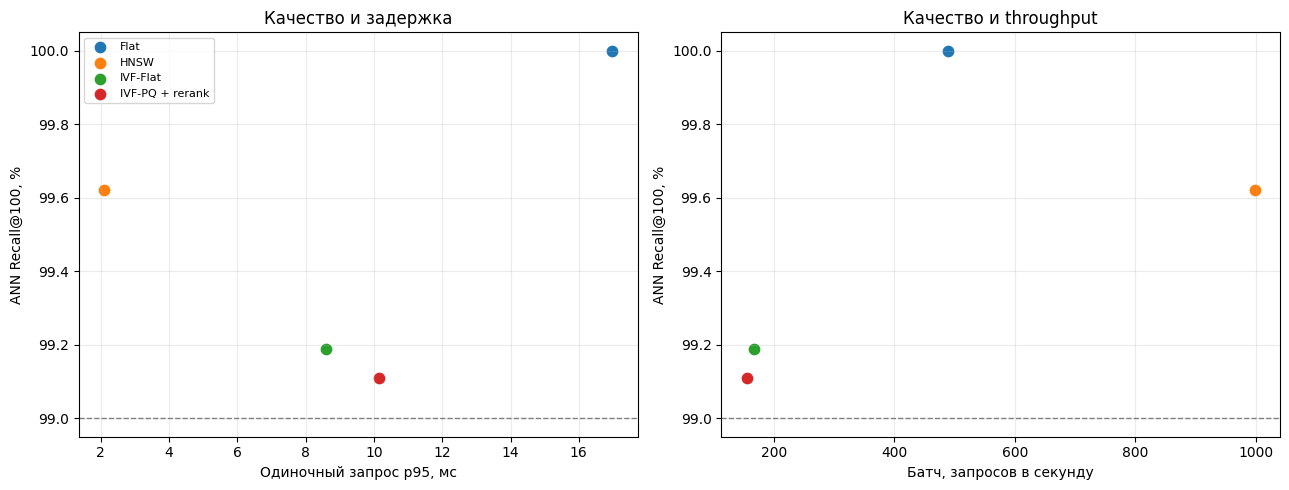

In [84]:
comparison = pd.DataFrame(results)
assert comparison['ann_recall'].min() >= TARGET_RECALL, comparison[['method', 'ann_recall']]
summary_columns = ['method', 'family', 'ann_recall', 'p50_ms', 'p95_ms', 'batch_qps', 'build_s']
display(best_results(comparison[summary_columns].sort_values('p95_ms')))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for family, group in comparison.groupby('family', sort=False):
    axes[0].scatter(group['p95_ms'], group['ann_recall'] * 100, label=family, s=55)
    axes[1].scatter(group['batch_qps'], group['ann_recall'] * 100, label=family, s=55)
axes[0].set(xlabel='Одиночный запрос p95, мс', ylabel='ANN Recall@100, %', title='Качество и задержка')
axes[1].set(xlabel='Батч, запросов в секунду', ylabel='ANN Recall@100, %', title='Качество и throughput')
for ax in axes:
    ax.axhline(TARGET_RECALL * 100, color='gray', linestyle='--', linewidth=1)
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

comparison.to_csv(ARTIFACT_DIR / 'benchmark_results.csv', index=False)
pd.DataFrame(tuning_results).to_csv(ARTIFACT_DIR / 'validation_results.csv', index=False)
shard_table.to_csv(ARTIFACT_DIR / 'sharding_results.csv', index=False)
pd.DataFrame(slow_rows).to_csv(ARTIFACT_DIR / 'slow_shard_results.csv', index=False)
metadata = {'profile': PROFILE, 'seed': SEED, 'items': n_items, 'dimension': dimension,
            'test_queries': N_QUERIES, 'validation_queries': N_VALIDATION, 'k': TOP_K,
            'metric': 'cosine via normalized inner product', 'target_recall': TARGET_RECALL,
            'threads': THREADS, 'nlist': NLIST, 'training_items': len(train_items),
            'faiss': faiss.__version__, 'numpy': np.__version__,
            'query_rows': query_rows.tolist(), 'validation_rows': validation_rows.tolist(),
            'training_rows': train_rows.tolist(), 'catalogue_rows': catalogue_rows.tolist()}
(ARTIFACT_DIR / 'run_metadata.json').write_text(json.dumps(metadata, indent=2));
